In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler,OneHotEncoder

In [3]:
# Carga de datos
df_path = 'C:/Users//DUOC/Desktop/test/actividad5/dataset/hotel_bookings.csv'
df = pd.read_csv(df_path)

In [4]:
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [5]:
df.shape

(119390, 32)

In [6]:
#con este describe tengo los numeros
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [7]:
df.dtypes

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [8]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [9]:
for columnas in df.columns:
    print("El numero de columnas vacias",columnas,"es de: ",df[columnas].isna().sum())

El numero de columnas vacias hotel es de:  0
El numero de columnas vacias is_canceled es de:  0
El numero de columnas vacias lead_time es de:  0
El numero de columnas vacias arrival_date_year es de:  0
El numero de columnas vacias arrival_date_month es de:  0
El numero de columnas vacias arrival_date_week_number es de:  0
El numero de columnas vacias arrival_date_day_of_month es de:  0
El numero de columnas vacias stays_in_weekend_nights es de:  0
El numero de columnas vacias stays_in_week_nights es de:  0
El numero de columnas vacias adults es de:  0
El numero de columnas vacias children es de:  4
El numero de columnas vacias babies es de:  0
El numero de columnas vacias meal es de:  0
El numero de columnas vacias country es de:  488
El numero de columnas vacias market_segment es de:  0
El numero de columnas vacias distribution_channel es de:  0
El numero de columnas vacias is_repeated_guest es de:  0
El numero de columnas vacias previous_cancellations es de:  0
El numero de columnas 

In [10]:
#caracteristicas
for columnas in df.columns:
    print("Nombre caracteristicas",columnas)

Nombre caracteristicas hotel
Nombre caracteristicas is_canceled
Nombre caracteristicas lead_time
Nombre caracteristicas arrival_date_year
Nombre caracteristicas arrival_date_month
Nombre caracteristicas arrival_date_week_number
Nombre caracteristicas arrival_date_day_of_month
Nombre caracteristicas stays_in_weekend_nights
Nombre caracteristicas stays_in_week_nights
Nombre caracteristicas adults
Nombre caracteristicas children
Nombre caracteristicas babies
Nombre caracteristicas meal
Nombre caracteristicas country
Nombre caracteristicas market_segment
Nombre caracteristicas distribution_channel
Nombre caracteristicas is_repeated_guest
Nombre caracteristicas previous_cancellations
Nombre caracteristicas previous_bookings_not_canceled
Nombre caracteristicas reserved_room_type
Nombre caracteristicas assigned_room_type
Nombre caracteristicas booking_changes
Nombre caracteristicas deposit_type
Nombre caracteristicas agent
Nombre caracteristicas company
Nombre caracteristicas days_in_waiting_

In [11]:
#caracteristicas
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [12]:
#Hago el respaldo
df2=df
print(type(df2))

<class 'pandas.core.frame.DataFrame'>


In [13]:
#ver cuantos datos tiene
df.shape

(119390, 32)

In [14]:
#esto no nos sirve se equivocaron, ahora hay que hacer otro respaldo ahora
df2=df2.dropna()
df2.shape

(217, 32)

In [15]:
#Nuevo respaldo para trabajar los datos
df3=df
df3.shape

(119390, 32)

In [16]:
#Con este describe tengo los objects
df.describe(include=[object])

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [17]:
df3['agent'].fillna(-999,inplace=True)
df3.head(5)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,-999.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,-999.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,-999.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [18]:
#Para hacer los gráficos debemos 
df3.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,-999.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,-999.0,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,-999.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [19]:
df3.shape

(119390, 32)

In [20]:
df3['country'].head(5)

0    PRT
1    PRT
2    GBR
3    GBR
4    GBR
Name: country, dtype: object

In [21]:
df3.groupby('hotel')['is_canceled'].sum() #Agrupa los que son hotel y cancelado y los suma (categorizado)

hotel
City Hotel      33102
Resort Hotel    11122
Name: is_canceled, dtype: int64

In [22]:
df3.groupby('arrival_date_month')['is_canceled'].sum()

arrival_date_month
April        4524
August       5239
December     2371
February     2696
January      1807
July         4742
June         4535
March        3149
May          4677
November     2122
October      4246
September    4116
Name: is_canceled, dtype: int64

In [31]:
def getGraficoBarras(label_x, label_y, title, feature):
    x_values = df3[feature].unique()
    y_values = df3[feature].value_counts().tolist()
    plt.bar(x_values, y_values)
    plt.title(title)
    plt.xlabel(label_x)
    plt.ylabel(label_y)
    plt.show()

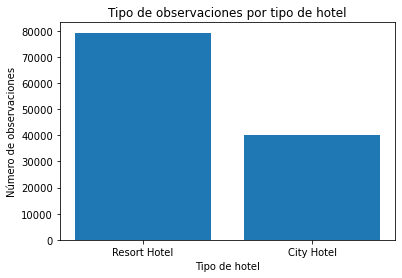

In [32]:
getGraficoBarras('Tipo de hotel','Número de observaciones','Tipo de observaciones por tipo de hotel','hotel')

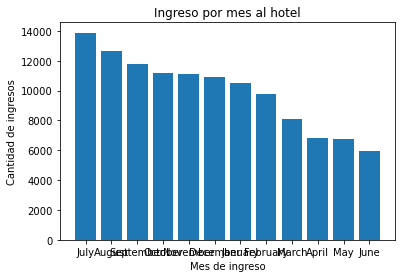

In [34]:
getGraficoBarras('Mes de ingreso','Cantidad de ingresos','Ingreso por mes al hotel','arrival_date_month')

In [36]:
df2.shape

(217, 32)

In [37]:
df2.to_csv('C:/Users//DUOC/Desktop/test/actividad5/dataset/hotel_respuesta.csv')